In [1]:
import numpy as np
from matplotlib import pyplot as plt
import enlighten
import shapely

from scipy.interpolate import interp1d

from utils import Modulator_CPW


from imodulator.ChargeSimulator import ChargeSimulatorSolcore
from imodulator.OpticalSimulator import OpticalSimulatorFEMWELL, OpticalSimulatorMODE
from imodulator.ElectroOpticalSimulator import ElectroOpticalSimulator
from imodulator.RFSimulator import RFSimulatorFEMWELL as RFSimulator

import skrf as rf

import os
import json

%matplotlib widget

Failed to import lumapi: [Errno 2] No such file or directory: 'C:/Program Files/Lumerical/v232/api/python/lumapi.py'


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\registries.py:73: UserWarning: Optics solver 'RCWA' will not be available. An installation of S4 has not been found.
  warn(
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\nextnanopy\defaults.py:202: UserWarning: Unsupported products in config file: ['nextnano.NEGF++'] will be ignored. To not see this message, please remove unsupported products from the config file: C:\Users\20230622\.nextnanopy-configNote: nextnano.NEGF++ was renamed to nextnano.NEGF, nextnano.NEGF was renamed to nextnano.NEGF_classic. Please check the documentation for more details.
  warnings.warn(


Successfully imported nextnanopy
Successfully configured nextnano++ settings
  [OK] nextnano++ exe: C:/Program Files/nextnano/2026_07_03/nextnano++/bin/nextnano++_Intel_64bit.exe
  [OK] nextnano++ license: C:/Users/20230622/OneDrive - TU Eindhoven/PhD/License_nnp.lic
  [OK] nextnano++ database: C:/Program Files/nextnano/2026_07_03/nextnano++/database/database.nnp
  [OK] nextnano++ outputdirectory: D:/Repos/imodulator/tests\nn_output
nextnano configuration test passed: all paths are valid.


In [2]:
from scipy.interpolate import CubicSpline

def extend_array(
        x,y, N=100
):

    f_interp = lambda t: CubicSpline(x,y.real, axis = 1)(t)  + 1j*CubicSpline(x,y.imag, axis =1)(t)
    
    x_new = np.linspace(np.min(x), np.max(x), N)
    y_new = f_interp(x_new)

    return y_new

def get_EO(
    freq,
    neff,
    loss,
    Z,
    L,
    ZS = 50,
    ZL = 50,
    N_new_freq = 100  ,
    no = 3.25
):
    
    loss_new = extend_array(freq, loss, N_new_freq)
    neff_new = extend_array(freq, neff, N_new_freq)
    Z_new = extend_array(freq, Z, N_new_freq)
    freq_new =  np.linspace(np.min(freq), np.max(freq), N_new_freq)
    
    alpha = loss_new*100 * np.log(10) / 20  # convert to Np/m
    beta = 2 * np.pi * freq_new * 1e9 * neff_new / 3e8  # in rad/m
    k = alpha + 1j * beta

    R_L = np.real(ZL)
    R_S = np.real(ZS)

    c_0 = 3e8  # speed of light in vacuum
    R_L = R_L
    R_G = R_S
    Z_0 = Z_new
    Z_L = ZL
    Z_G = ZS

    Z_in = Z_0 * (Z_L + Z_0 * np.tanh(k*L)) / (Z_0 + Z_L * np.tanh(k*L)) #RF line input impedance 
    w= freq_new*2*np.pi*1e9
    u_p = (alpha*L) + (1j* w)*(neff_new-no)*L /(c_0)
    u_m = -(alpha*L) + (1j* w)*(-neff_new-no)*L /(c_0)
    fu_p = (1 - np.exp(u_p)) / u_p
    fu_m = (1 - np.exp(u_m)) / u_m
    mw = (
        ((R_L + R_G) / R_L)
        * np.absolute(Z_in / (Z_in + Z_G))
        * np.absolute(
            (((Z_L + Z_0) * fu_p) + ((Z_L - Z_0) * fu_m))
            / (
                ((Z_L + Z_0) * np.exp(k * L))
                + ((Z_L - Z_0) * np.exp(-k * L))
            )
        )
    )
    return 20*np.log10(mw) #The factor of 20log10 is because we want to consider the EO bandwidth as the power of an electrical signal generated by the optical power, like the current of a perfect photodiode.

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)


(<Figure size 640x480 with 1 Axes>, <Axes: >)

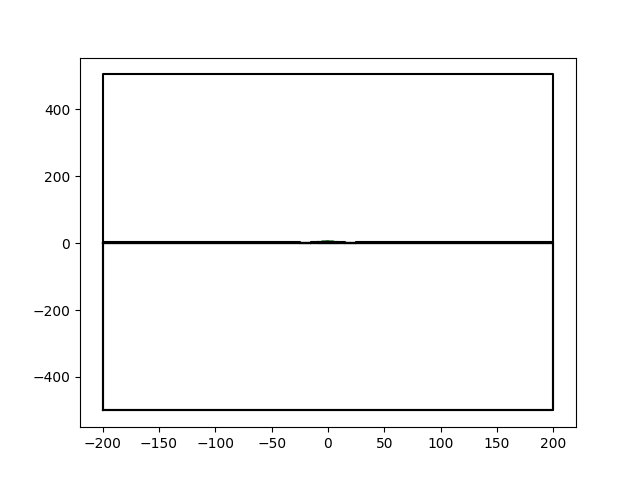

In [3]:
modulator = Modulator_CPW()
modulator.device.plot_polygons()

In [4]:
np.linspace(0,8,33)

array([0.  , 0.25, 0.5 , 0.75, 1.  , 1.25, 1.5 , 1.75, 2.  , 2.25, 2.5 ,
       2.75, 3.  , 3.25, 3.5 , 3.75, 4.  , 4.25, 4.5 , 4.75, 5.  , 5.25,
       5.5 , 5.75, 6.  , 6.25, 6.5 , 6.75, 7.  , 7.25, 7.5 , 7.75, 8.  ])

Charge transport will take place with:
L6
L5
L5_1
L4
L3
L2
bcbp
Material "L2" does not have k-data defined. Returning "zeros"
Material "L3" does not have k-data defined. Returning "zeros"
Material "L4" does not have k-data defined. Returning "zeros"
Material "L5_1" does not have k-data defined. Returning "zeros"
Material "L5" does not have k-data defined. Returning "zeros"
Material "L6" does not have k-data defined. Returning "zeros"
Solving IV of the junctions...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Solving IV of the tunnel junctions...
Solving IV of the total solar cell...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


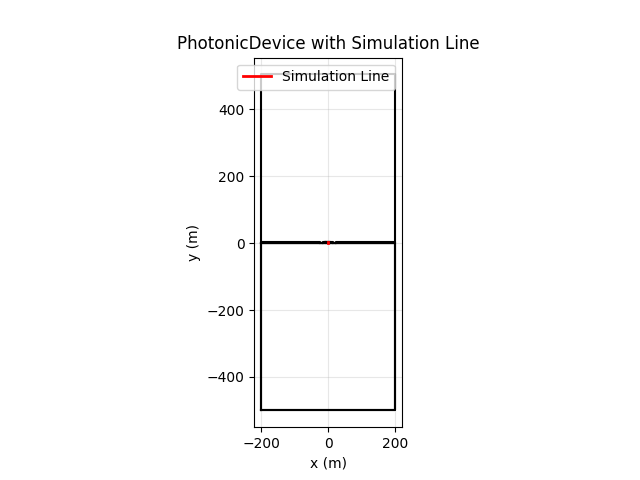

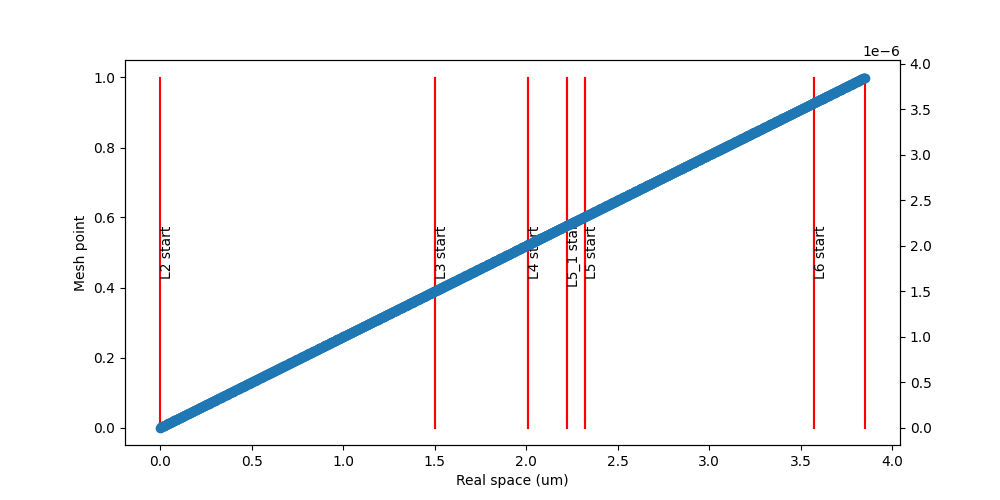

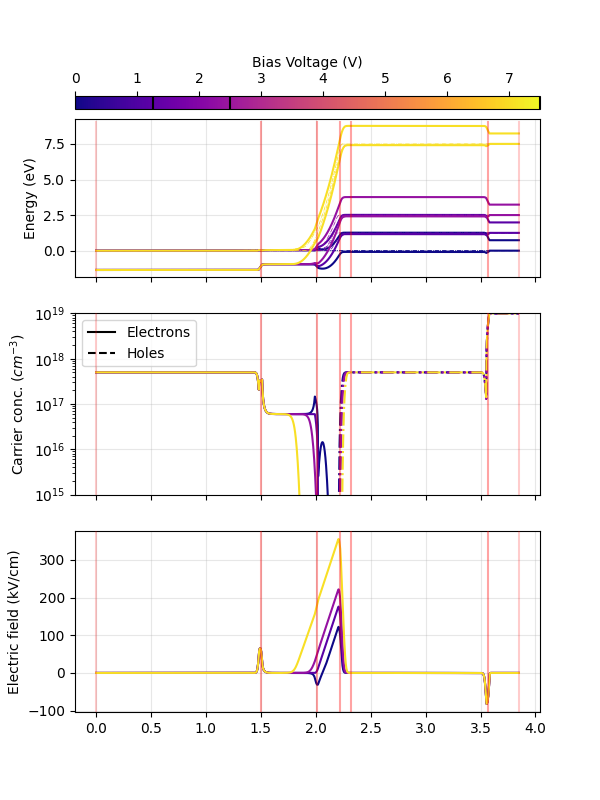

In [5]:
a=shapely.LineString([
    [0,0+0.001],
    [0,modulator.h_L1 + modulator.h_L2+modulator.h_L3+modulator.h_L4+modulator.h_L5+modulator.h_L5_1+modulator.h_L6-0.001]])
 
charge=ChargeSimulatorSolcore(
    device=modulator.device,
    simulation_line=a,
    bias_start_stop_step=[0,8,33]
)

fig, ax = charge.plot_with_simulation_line()
charge.plot_mesh()

charge.solve_PDD(
    verbose = True*0,
    tol = 1e-6,
    max_iter = 1000,
    smooth_output=True,
    savgol_window = 10
)

charge.plot_results(
    V_idx = [0, 5, 10, 30],
    cmap = 'plasma'
)
charge.transfer_results_to_device(
	dx = 0.5,
	polygons_to_map = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L5_1'])

Number of mesh elements: 4852


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(
C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Python packages\Imodulator\src\imodulator\RFSimulator.py:526: RuntimeWarning: divide by zero encountered in log10
  data_to_plot_im = np.log10(-data_to_plot_im)


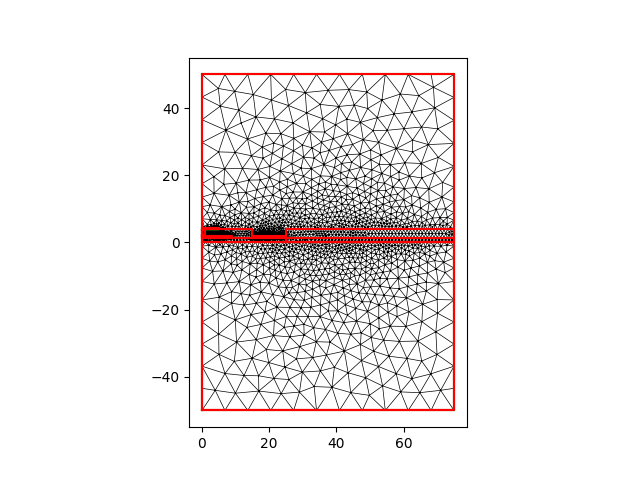

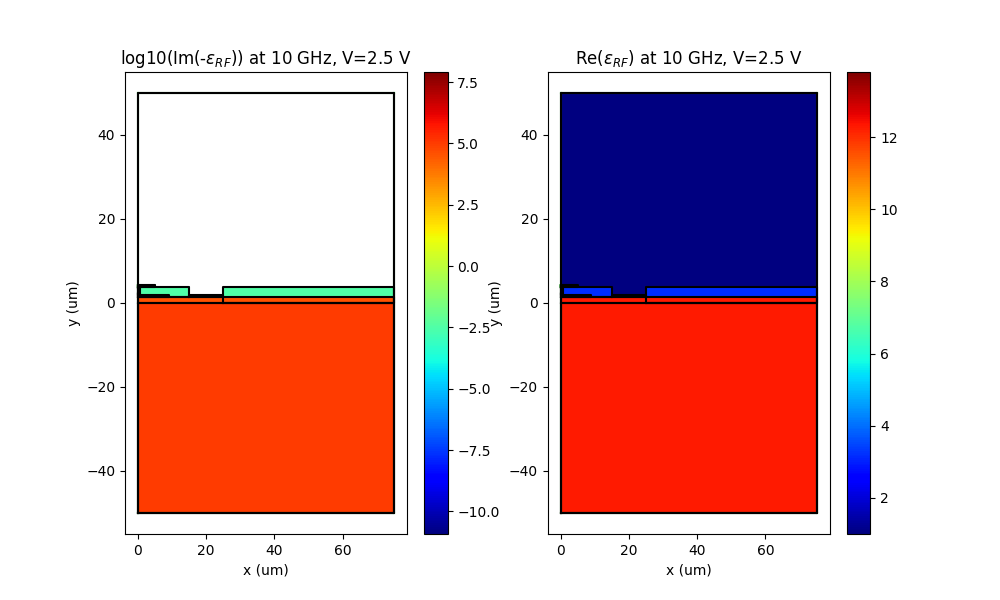

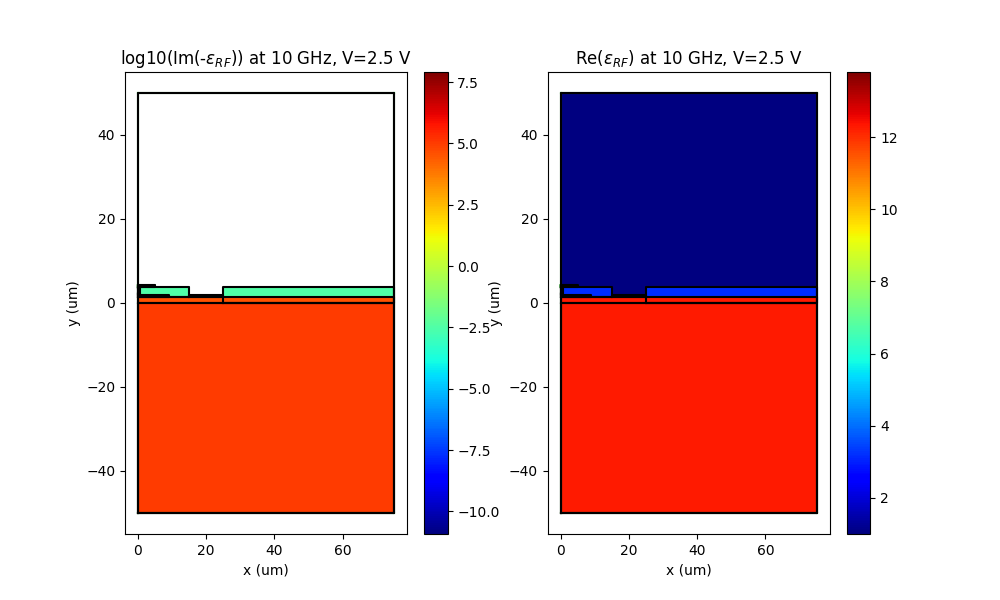

In [6]:
rf_sim = RFSimulator(modulator.device, simulation_window=shapely.box(0, -50, 75, 50))
rf_sim.make_mesh(
                gmsh_algorithm=1,
                verbose=True
            )
print(f"Number of mesh elements: {rf_sim.mesh.nelements}")
rf_sim.plot_mesh()
_ = rf_sim.plot_eps_rf(
    frequency=10, #GHz
    log_scale_re=False,
    log_scale_im=True,
    use_charge_transport_data=True,
    voltage_idx=10
)

fig, ax1, ax2 = rf_sim.plot_eps_rf(
    frequency=10, #GHz
    log_scale_re=False,
    log_scale_im=True,
    use_charge_transport_data=True,
    voltage_idx=10
)

Effective index - mode 0: 8.7773-5.0579j
loss - mode 0: 9.20 dB/cm
power:  (1.0000000000000002+0j)
TE fraction:  0.1491415623855653
TM fraction:  0.8508584376144347
transversality: 0.9999997052248301
#------------------------------------------#


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\skfem\assembly\form\linear_form.py:44: ComplexWarning: Casting complex values to real discards the imaginary part
  data[ixs] = self._kernel(vbasis.basis[i], w, dx)


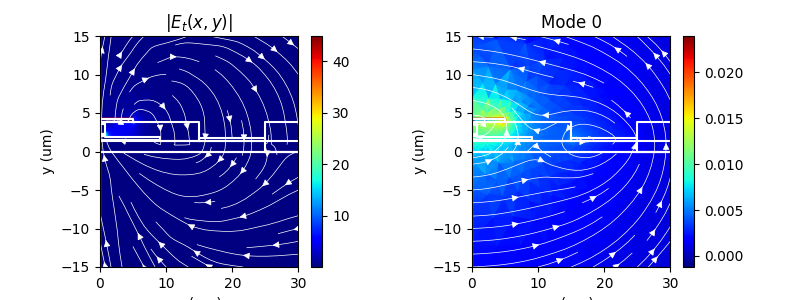

In [7]:
modes = rf_sim.compute_modes(
        frequency = 1,
        metallic_boundaries = ['bottom','top','right'],
        n_guess = 6,
        num_modes = 1,
        order = 1,
        return_modes = True,
        use_charge_transport_data=True,
        voltage_idx=8
    )

for i in range(len(modes)):
    print(f'Effective index - mode {i}: {modes[i].n_eff:.4f}')
    print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
    print(f"power: ", modes[i].calculate_power())
    print(f"TE fraction: ", modes[i].te_fraction)
    print(f"TM fraction: ", modes[i].tm_fraction)
    print(f"transversality: {modes[i].transversality}")
    print('#------------------------------------------#')



for i in range(len(modes)):
    rf_sim.plot_mode(
        modes[i],
        xmin = 0, xmax = 30, ymin = -15, ymax = 15, plot_vectors=True,
        figsize=(8,3),
        cmap = 'jet',
        color_vectors = 'white',
        vector_density = 0.65
    )
    ax = plt.gca()
    ax.set_title(f'Mode {i}')

In [8]:
## mesh refinement
freq_refinement = 1 #GHz, we want to optimize for the EO response at this frequency
N_mesh_refinement = 50 # Maximum number of mesh refinement steps
N_elements_max = 15_000 #Maximum number of mesh elements. Refinement stops when either N_mesh refinement steps are reached or the number of mesh elements exceeds N_elements_max
n_modes = 1 #We only want the fundamental mode for the RF simulation

n_elements_refinement = np.zeros(N_mesh_refinement)
neff_values_refinement = np.zeros(N_mesh_refinement)
loss_values_refinement = np.zeros(N_mesh_refinement)
Z0_values_refinement = np.zeros(N_mesh_refinement, dtype=complex)

boundary_conditions = ['bottom','top','right']

for i in range(N_mesh_refinement):
    if i>8:
        freq_refinement = 20 #GHz

    elif i>15:
        freq_refinement = 35 #GHz
        
    #Compute modes
    modes2 = rf_sim.compute_modes(
        frequency = freq_refinement,
        metallic_boundaries = boundary_conditions,
        n_guess = 6,
        num_modes = n_modes,
        order = 1,
        return_modes = True,
        use_charge_transport_data=True,
        voltage_idx=8
    )

    idx_mode=0

    ######### Calculate characteristic impedance #########
    p0, i0_all, _ = rf_sim.get_currents(mode = rf_sim.modes[idx_mode])
    # print(i0_all)

    I0 = 2*i0_all['sig_metal_line_current'] #<--- This is crucial!

    p0 = 2*p0 
    Z0 = p0/np.abs(I0)**2

    rf_sim.refine_mesh(
        mode_for_refinement=rf_sim.modes[idx_mode], 
        N_nearest_neighbours=500
    )

    neff_values_refinement[i] = rf_sim.modes[idx_mode].n_eff.real
    loss_values_refinement[i] = rf_sim.modes[idx_mode].calculate_propagation_loss(1e4)
    Z0_values_refinement[i] = Z0
    n_elements_refinement[i] = rf_sim.mesh.nelements

    if rf_sim.mesh.nelements > N_elements_max:
        print("Reached maximum number of elements. Stopping refinement.")
        break

    print(f"Refinement step {i+1}/{N_mesh_refinement}: n_elements = {rf_sim.mesh.nelements}, n_eff = {neff_values_refinement[i]:.4f}, loss = {loss_values_refinement[i]:.2f} dB/cm, Z0 = {Z0_values_refinement[i]:.2f} Ohm")

neff_values_refinement = neff_values_refinement[:i+1]
loss_values_refinement = loss_values_refinement[:i+1]
Z0_values_refinement = Z0_values_refinement[:i+1]
n_elements_refinement = n_elements_refinement[:i+1]

Refinement step 1/50: n_elements = 4981, n_eff = 8.7773, loss = 9.20 dB/cm, Z0 = 43.98-24.91j Ohm
Refinement step 2/50: n_elements = 5207, n_eff = 8.7528, loss = 9.20 dB/cm, Z0 = 44.04-24.87j Ohm
Refinement step 3/50: n_elements = 5291, n_eff = 9.2078, loss = 9.74 dB/cm, Z0 = 41.66-23.39j Ohm
Refinement step 4/50: n_elements = 5927, n_eff = 9.2035, loss = 9.73 dB/cm, Z0 = 41.48-23.29j Ohm
Refinement step 5/50: n_elements = 5993, n_eff = 8.9568, loss = 9.53 dB/cm, Z0 = 42.35-23.62j Ohm
Refinement step 6/50: n_elements = 6308, n_eff = 8.9426, loss = 9.51 dB/cm, Z0 = 42.45-23.69j Ohm
Refinement step 7/50: n_elements = 7912, n_eff = 8.9397, loss = 9.51 dB/cm, Z0 = 41.81-23.32j Ohm
Refinement step 8/50: n_elements = 8162, n_eff = 8.9489, loss = 9.58 dB/cm, Z0 = 39.59-21.90j Ohm
Refinement step 9/50: n_elements = 8896, n_eff = 8.9488, loss = 9.58 dB/cm, Z0 = 39.21-21.69j Ohm
Refinement step 10/50: n_elements = 9636, n_eff = 6.1733, loss = 48.51 dB/cm, Z0 = 27.16-1.35j Ohm
Refinement step 11/

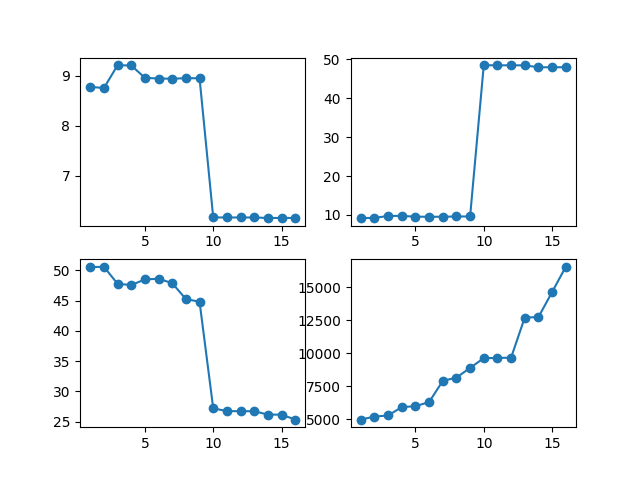

In [9]:
fig = plt.figure()
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])


n_iterations = np.arange(1, len(neff_values_refinement)+1)

ax1.plot(n_iterations, neff_values_refinement, marker='o')
ax2.plot(n_iterations, loss_values_refinement, marker='o')
ax3.plot(n_iterations, np.abs(Z0_values_refinement), marker='o')
ax4.plot(n_iterations, n_elements_refinement, marker='o')

Effective index - mode 0: 7.3562-3.7159j
loss - mode 0: 10.14 dB/cm
power:  (0.9999999999999998+0j)
TE fraction:  0.16244756121519477
TM fraction:  0.8375524387848052
transversality: 0.9999995072940303
#------------------------------------------#


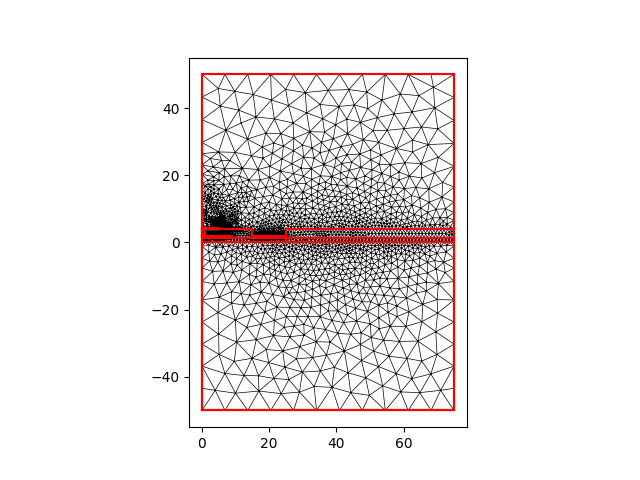

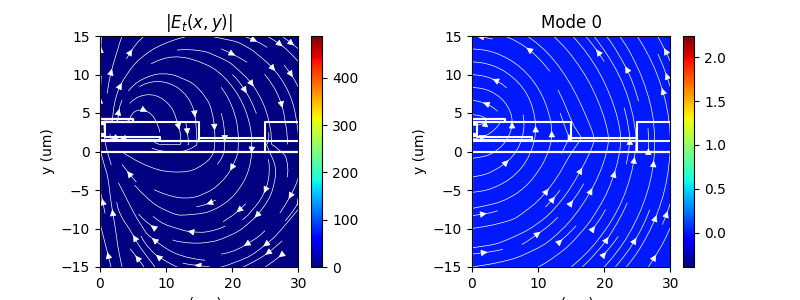

In [10]:
rf_sim.plot_mesh()

modes = rf_sim.compute_modes(
        frequency = 1.5,
        metallic_boundaries = ['bottom','top','right'],
        n_guess = 10,
        num_modes = 1,
        order = 1,
        return_modes = True,
        use_charge_transport_data=True,
        voltage_idx=int(len(modulator.device.charge['V'])/2)
    )

for i in range(len(modes)):
    print(f'Effective index - mode {i}: {modes[i].n_eff:.4f}')
    print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
    print(f"power: ", modes[i].calculate_power())
    print(f"TE fraction: ", modes[i].te_fraction)
    print(f"TM fraction: ", modes[i].tm_fraction)
    print(f"transversality: {modes[i].transversality}")
    print('#------------------------------------------#')



for i in range(len(modes)):
    rf_sim.plot_mode(
        modes[i],
        xmin = 0, xmax = 30, ymin = -15, ymax = 15, plot_vectors=True,
        figsize=(8,3),
        cmap = 'jet',
        color_vectors = 'white',
        vector_density = 0.65
    )
    ax = plt.gca()
    ax.set_title(f'Mode {i}')
    

<Axes: title={'center': 'Ex (real. part)'}>

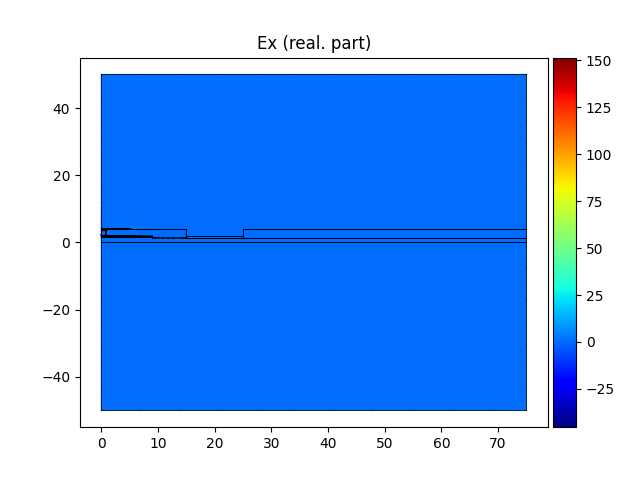

In [11]:
rf_sim.modes[0].plot_component('E', 'x', colorbar=True)

In [12]:
rf_sim.photodevice.charge['V'][[8,10,12,14, 16]]

array([2. , 2.5, 3. , 3.5, 4. ])

In [13]:
freq_values = np.linspace(1, 40, 50) #GHz
# voltage_idxs = np.arange(1,len(modulator.device.charge['V']),1)
voltage_idxs = np.asarray([8,10,12,14, 16])

S11_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)
S12_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)
EO_values = np.zeros((len(voltage_idxs), len(freq_values)))
neff_values = np.zeros((len(voltage_idxs), len(freq_values)))
loss_values = np.zeros((len(voltage_idxs), len(freq_values)))
Z0_values = np.zeros((len(voltage_idxs), len(freq_values)), dtype=complex)

for j, voltage_idx in enumerate(voltage_idxs):
    for freq_idx, freq in enumerate(freq_values):
        print(f"Calculating S-parameters for voltage index {voltage_idx} and frequency {freq} GHz")
        modes = rf_sim.compute_modes(
            frequency = freq,
            metallic_boundaries = boundary_conditions,
            n_guess = 6,
            num_modes = n_modes,
            order = 1,
            return_modes = True,
            use_charge_transport_data=True,
            voltage_idx=voltage_idx
        )

        idx_mode=0

        ######### Calculate characteristic impedance #########
        p0, i0_all, _ = rf_sim.get_currents(mode = rf_sim.modes[idx_mode])
        I0 = 2*i0_all['sig_metal_line_current'] #<--- This is crucial!

        p0 = 2*p0
        Z0 = p0/np.abs(I0)**2

        neff_values[j, freq_idx] = rf_sim.modes[idx_mode].n_eff.real
        loss_values[j, freq_idx] = rf_sim.modes[idx_mode].calculate_propagation_loss(1e4)
        Z0_values[j, freq_idx] = Z0

        s11, s12 = rf_sim.get_S(
                rf_sim.modes[idx_mode].k,
                Z = Z0_values[j, freq_idx],
                ZL = 50,
                ZS = 50,
                L = 1.25e3 #um
            )
        S11_values[j, freq_idx] = s11
        S12_values[j, freq_idx] = s12

    eo = get_EO(
        freq_values,
        neff_values[j],
        loss_values[j],
        Z0_values[j],
        1.25e-3,
        N_new_freq=len(freq_values),
        no=3.6
    )

    EO_values[j] = eo

Calculating S-parameters for voltage index 8 and frequency 1.0 GHz
Calculating S-parameters for voltage index 8 and frequency 1.7959183673469388 GHz
Calculating S-parameters for voltage index 8 and frequency 2.5918367346938775 GHz
Calculating S-parameters for voltage index 8 and frequency 3.387755102040816 GHz
Calculating S-parameters for voltage index 8 and frequency 4.183673469387755 GHz
Calculating S-parameters for voltage index 8 and frequency 4.979591836734694 GHz
Calculating S-parameters for voltage index 8 and frequency 5.775510204081632 GHz
Calculating S-parameters for voltage index 8 and frequency 6.571428571428571 GHz
Calculating S-parameters for voltage index 8 and frequency 7.36734693877551 GHz
Calculating S-parameters for voltage index 8 and frequency 8.16326530612245 GHz
Calculating S-parameters for voltage index 8 and frequency 8.959183673469388 GHz
Calculating S-parameters for voltage index 8 and frequency 9.755102040816327 GHz
Calculating S-parameters for voltage index

In [16]:
np.save(
	'RF_data.npy',
	{
		'freq_values': freq_values,
        'voltage_idxs': voltage_idxs,
        'voltage_values': modulator.device.charge['V'][voltage_idxs],
        'S11_values': S11_values,
        'S12_values': S12_values,
        'EO_values': EO_values,
		'neff_values': neff_values,
        'loss_values': loss_values,
        'Z0_values': Z0_values
    }
)

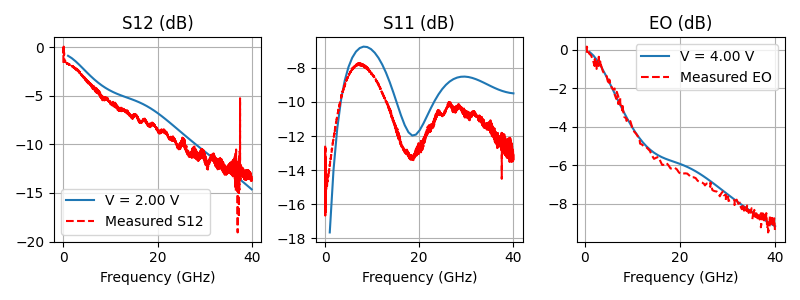

: 

In [ ]:
import os
import skrf as rf
CWD = os.getcwd()

ntwk = rf.Network(r'C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Reports and papers\16. Imodulator paper\Generic_InP\Yao_2017\PM1_2V.s2p')

freq = ntwk.frequency.f
s11 = ntwk.s[:,0,0]
s12 = ntwk.s[:,1,0]

eo_meas = np.loadtxt(r'C:\Users\20230622\OneDrive - TU Eindhoven\PhD\Reports and papers\16. Imodulator paper\Generic_InP\Yao_2017\EO_data.csv', delimiter=',')

fig = plt.figure(figsize=(8, 3))
gs = fig.add_gridspec(1, 3)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

for i in [0]:
    ax1.plot(freq_values, 20*np.log10(np.abs(S12_values[i])), label=f'V = {modulator.device.charge["V"][voltage_idxs[i]]:.2f} V')
    ax2.plot(freq_values, 20*np.log10(np.abs(S11_values[i])), label=f'V = {modulator.device.charge["V"][voltage_idxs[i]]:.2f} V')

i=4
ax3.plot(freq_values, EO_values[i], label=f'V = {modulator.device.charge["V"][voltage_idxs[i]]:.2f} V')

ax1.plot(freq/1e9, 20*np.log10(np.abs(s12)), label='Measured S12', linestyle='--', color='red')
ax2.plot(freq/1e9, 20*np.log10(np.abs(s11)), label='Measured S11', linestyle='--', color='red')
ax3.plot(eo_meas[:,0], eo_meas[:,1], label='Measured EO', linestyle='--', color='red')

ax1.set_title('S12 (dB)')
ax2.set_title('S11 (dB)')
ax3.set_title('EO (dB)')
ax1.set_xlabel('Frequency (GHz)')
ax2.set_xlabel('Frequency (GHz)')
ax3.set_xlabel('Frequency (GHz)')

ax1.grid()
ax2.grid()
ax3.grid()

ax1.legend()
ax3.legend()

fig.tight_layout()

The deviation from measurements can be attributed to unknown details on the fab. In particular the metal thickness will have a big influence as even deviations as small as 100nm for a thickness of 400nm will result in significant change in the propagation cosntant of the microwave. Furthermore, the S parameters measurements are not deembeded and include the effect of the probe pads. That is why the EO shows a much better agreement than the EE.

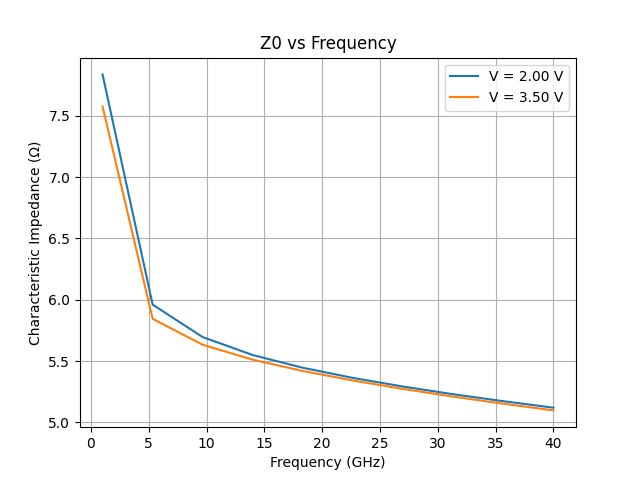

In [ ]:
plt.figure()
for i in range(len(voltage_idxs)):
    plt.plot(freq_values, neff_values[i], label=f'V = {modulator.device.charge["V"][voltage_idxs[i]]:.2f} V')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Characteristic Impedance (Ω)')
plt.title('Z0 vs Frequency')
plt.legend()
plt.grid()


(<Figure size 640x480 with 1 Axes>, <Axes: >)

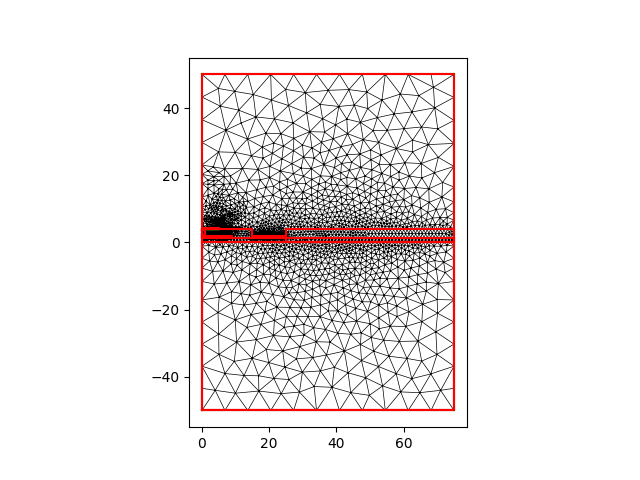

In [ ]:
rf_sim.plot_mesh()